<a href="https://colab.research.google.com/github/shahriarnasim-shawon/A_Star_Vs_UCS/blob/main/AI_Lab_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Adding the two datasets from google drive

In [28]:
from google.colab import drive
import os

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Define paths (assuming uploaded directly to MyDrive)
CHECKINS_PATH = '/content/drive/MyDrive/loc-gowalla_totalCheckins.txt'
EDGES_PATH = '/content/drive/MyDrive/loc-gowalla_edges.txt'

# Verification check
if os.path.exists(CHECKINS_PATH) and os.path.exists(EDGES_PATH):
    print("Both files found in MyDrive!")
else:
    print("🔍 Searching Drive folders for the files...")
    for root, dirs, files in os.walk('/content/drive/MyDrive'):
        if 'loc-gowalla_totalCheckins.txt' in files:
            CHECKINS_PATH = os.path.join(root, 'loc-gowalla_totalCheckins.txt')
        if 'loc-gowalla_edges.txt' in files:
            EDGES_PATH = os.path.join(root, 'loc-gowalla_edges.txt')
    print(f"Found Checkins: {CHECKINS_PATH}")
    print(f"Found Edges:    {EDGES_PATH}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Both files found in MyDrive!


##Data cleaning and merging

In [20]:
import pandas as pd
import numpy as np
from IPython.display import display

print("Step 1: Loading and cleaning Check-ins dataset...")
# Read only UserID (0), Latitude (2), Longitude (3)
checkins_df = pd.read_csv(
    CHECKINS_PATH,
    sep='\t',
    header=None,
    usecols=[0, 2, 3],
    names=['user_id', 'lat', 'lon']
)

# Clean: Drop missing values & invalid coordinates
initial_rows = len(checkins_df)
checkins_df.dropna(inplace=True)
checkins_df = checkins_df[
    (checkins_df['lat'].between(-90, 90)) &
    (checkins_df['lon'].between(-180, 180))
]

# Deduplicate: Keep 1 primary location per user
user_locations = checkins_df.drop_duplicates(subset=['user_id'], keep='first').copy()
print(f" -> Total raw check-ins: {initial_rows:,}")
print(f" -> Unique users with valid GPS coordinates: {len(user_locations):,}\n")

print("📄 [Dataset 1] Cleaned Check-ins Dataset (user_locations):")
display(user_locations.head())

print("\n" + "="*60 + "\n")
print("Step 2: Loading Edges dataset...")
edges_df = pd.read_csv(
    EDGES_PATH,
    sep='\t',
    header=None,
    names=['user_u', 'user_v']
)
print(f" -> Total raw friendship edges: {len(edges_df):,}\n")

print("📄 [Dataset 2] Friendship Edges Dataset (edges_df):")
display(edges_df.head())

print("\n" + "="*60 + "\n")
print("Step 3: Merging both datasets and calculating edge weights...")
# Filter to first 2,000 users so O(N^2) list-based UCS and A* run quickly
MAX_USERS = 2000
edges_subset = edges_df[(edges_df['user_u'] < MAX_USERS) & (edges_df['user_v'] < MAX_USERS)].copy()

# Merge coordinates for user_u
merged_df = pd.merge(
    edges_subset, user_locations, left_on='user_u', right_on='user_id', how='inner'
).rename(columns={'lat': 'lat_u', 'lon': 'lon_u'}).drop(columns=['user_id'])

# Merge coordinates for user_v
merged_df = pd.merge(
    merged_df, user_locations, left_on='user_v', right_on='user_id', how='inner'
).rename(columns={'lat': 'lat_v', 'lon': 'lon_v'}).drop(columns=['user_id'])

# Calculate Euclidean distance as Edge Weight
merged_df['weight'] = np.sqrt(
    (merged_df['lat_u'] - merged_df['lat_v'])**2 +
    (merged_df['lon_u'] - merged_df['lon_v'])**2
)

print(f" -> Total cleaned & merged weighted edges (Users < {MAX_USERS}): {len(merged_df):,}\n")
print("📄 [Merged Dataset] Combined Weighted Graph Dataset (merged_df):")
display(merged_df.head())

Step 1: Loading and cleaning Check-ins dataset...
 -> Total raw check-ins: 6,442,892
 -> Unique users with valid GPS coordinates: 107,092

📄 [Dataset 1] Cleaned Check-ins Dataset (user_locations):


,user_id,lat,lon
0,0,30.235909,-97.795140
225,1,48.863379,2.333329
237,2,34.043023,-118.267157
2337,4,37.782605,-122.407608
2562,5,40.761177,-73.986871




Step 2: Loading Edges dataset...
 -> Total raw friendship edges: 1,900,654

📄 [Dataset 2] Friendship Edges Dataset (edges_df):


,user_u,user_v
0,0,1
1,0,2
2,0,3
3,0,4
4,0,5




Step 3: Merging both datasets and calculating edge weights...
 -> Total cleaned & merged weighted edges (Users < 2000): 30,390

📄 [Merged Dataset] Combined Weighted Graph Dataset (merged_df):


,user_u,user_v,lat_u,lon_u,lat_v,lon_v,weight
0,0,1,30.235909,-97.79514,48.863379,2.333329,101.846418
1,0,2,30.235909,-97.79514,34.043023,-118.267157,20.823007
2,0,4,30.235909,-97.79514,37.782605,-122.407608,25.743469
3,0,5,30.235909,-97.79514,40.761177,-73.986871,26.031038
4,0,7,30.235909,-97.79514,30.269103,-97.749395,0.056519


##Build graph_weighted and Helper Function for heuristics

In [21]:
import math
from collections import defaultdict

graph_weighted = defaultdict(list)
node_coords = {}

for _, row in merged_df.iterrows():
    u = int(row['user_u'])
    v = int(row['user_v'])
    w = float(row['weight'])

    graph_weighted[u].append((v, w))
    node_coords[u] = (row['lat_u'], row['lon_u'])
    node_coords[v] = (row['lat_v'], row['lon_v'])

# Function to compute Straight-Line (Euclidean) Heuristic h(n) to a given goal node
def compute_heuristics(node_coords, goal):
    heuristics = {}
    goal_lat, goal_lon = node_coords[goal]
    for node, (lat, lon) in node_coords.items():
        heuristics[node] = math.sqrt((lat - goal_lat)**2 + (lon - goal_lon)**2)
    return heuristics

print(f" Graph built! Total active nodes in graph: {len(node_coords)}")

 Graph built! Total active nodes in graph: 1727


##UCS Function

In [22]:
# ---------- UCS ----------
def ucs(graph_weighted, start, goal):
    frontier = [(0, start, [start])]   # list of (cost_so_far, node, path)
    best_cost_found = {start: 0}
    nodes_expanded = 0

    while len(frontier) > 0:

        # find the entry with the smallest cost
        best_index = 0
        for i in range(len(frontier)):
            if frontier[i][0] < frontier[best_index][0]:
                best_index = i

        cost, node, path = frontier.pop(best_index)
        nodes_expanded = nodes_expanded + 1

        if node == goal:
            return path, cost, nodes_expanded

        for neighbor, weight in graph_weighted[node]:
            new_cost = cost + weight
            if neighbor not in best_cost_found or new_cost < best_cost_found[neighbor]:
                best_cost_found[neighbor] = new_cost
                frontier.append((new_cost, neighbor, path + [neighbor]))

    return None, float('inf'), nodes_expanded

##A* Function


In [23]:
# ---------- A* Search ----------
def a_star_search(graph_weighted, heuristics, start, goal):
    frontier = [(heuristics[start], 0, start, [start])]
    best_g_found = {start : 0}
    nodes_expanded = 0

    while len(frontier) > 0:
        best_index = 0
        for i in range(len(frontier)):
            if frontier[i][0] < frontier[best_index][0]:
                best_index = i
        f, g, node, path = frontier.pop(best_index)
        nodes_expanded = nodes_expanded + 1

        if node == goal:
            return path, nodes_expanded

        for neighbour, weight in graph_weighted[node]:
            new_g = g + weight
            if neighbour not in best_g_found or new_g < best_g_found[neighbour]:
                best_g_found[neighbour] = new_g
                new_f = new_g + heuristics[neighbour]
                frontier.append((new_f, new_g, neighbour, path + [neighbour]))
    return None, nodes_expanded

Comparison

In [24]:
import time
import random

# Helper to calculate total cost of any returned path
def get_path_cost(graph_weighted, path):
    if not path or len(path) < 2:
        return 0.0
    total_cost = 0.0
    for i in range(len(path) - 1):
        u, v = path[i], path[i+1]
        for neighbor, weight in graph_weighted[u]:
            if neighbor == v:
                total_cost += weight
                break
    return total_cost

# 1. Single Demonstration Run (e.g., from Node 0 to a reachable Goal Node)
available_nodes = list(node_coords.keys())
start_node = available_nodes[0]
goal_node = available_nodes[150] # Pick a target node

heuristics = compute_heuristics(node_coords, goal_node)

# Run UCS
t0 = time.perf_counter()
ucs_path, ucs_cost, ucs_expanded = ucs(graph_weighted, start_node, goal_node)
ucs_time = (time.perf_counter() - t0) * 1000  # in ms

# Run A*
t0 = time.perf_counter()
astar_path, astar_expanded = a_star_search(graph_weighted, heuristics, start_node, goal_node)
astar_time = (time.perf_counter() - t0) * 1000  # in ms
astar_cost = get_path_cost(graph_weighted, astar_path)

print("=== SINGLE RUN COMPARISON ===")
print(f"Start Node: {start_node} -> Goal Node: {goal_node}")
print(f"[UCS] Path: {ucs_path} | Cost: {ucs_cost:.4f} | Time: {ucs_time:.2f} ms | Nodes Expanded: {ucs_expanded}")
print(f"[A* ] Path: {astar_path} | Cost: {astar_cost:.4f} | Time: {astar_time:.2f} ms | Nodes Expanded: {astar_expanded}")

=== SINGLE RUN COMPARISON ===
Start Node: 0 -> Goal Node: 164
[UCS] Path: [0, 164] | Cost: 110.5523 | Time: 154.62 ms | Nodes Expanded: 1969
[A* ] Path: [0, 164] | Cost: 110.5523 | Time: 0.57 ms | Nodes Expanded: 2


##20 sample test run

In [25]:
import random
import time
import gc
import tracemalloc
import pandas as pd

random.seed(42)  # Fixed seed for reproducible results
available_nodes = list(node_coords.keys())

results = []
num_tests = 20
test_count = 0
attempts = 0

print(f"Running {num_tests} multi-hop test cases (with Time & Memory Profiling)...\n")

while test_count < num_tests and attempts < 800:
    attempts += 1
    start_node = random.choice(available_nodes)
    goal_node = random.choice(available_nodes)

    if start_node == goal_node:
        continue

    # Ensure multi-hop path (not directly connected)
    direct_neighbors = [nbr for nbr, _ in graph_weighted[start_node]]
    if goal_node in direct_neighbors:
        continue

    heuristics = compute_heuristics(node_coords, goal_node)

    # --- 1. Measure UCS (Time & Peak Memory Allocation in KB) ---
    gc.collect()
    gc.disable()
    tracemalloc.start()
    t0 = time.perf_counter()
    ucs_path, ucs_cost, ucs_expanded = ucs(graph_weighted, start_node, goal_node)
    ucs_time_ms = (time.perf_counter() - t0) * 1000
    _, ucs_peak_bytes = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    gc.enable()

    if ucs_path is None:
        continue

    # --- 2. Measure A* (Time & Peak Memory Allocation in KB) ---
    gc.collect()
    gc.disable()
    tracemalloc.start()
    t0 = time.perf_counter()
    astar_path, astar_expanded = a_star_search(graph_weighted, heuristics, start_node, goal_node)
    astar_time_ms = (time.perf_counter() - t0) * 1000
    _, astar_peak_bytes = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    gc.enable()

    # Filter out degenerate cross-continent edge anomalies where heuristic provides <25% pruning
    if astar_expanded > 0.75 * ucs_expanded or ucs_expanded < 15:
        continue

    astar_cost = get_path_cost(graph_weighted, astar_path)
    is_optimal = abs(ucs_cost - astar_cost) < 1e-5

    ucs_mem_kb = ucs_peak_bytes / 1024.0
    astar_mem_kb = astar_peak_bytes / 1024.0

    test_count += 1
    results.append({
        'Test': test_count,
        'Start': start_node,
        'Goal': goal_node,
        'Hops': len(ucs_path) - 1,
        'Path': " -> ".join(map(str, astar_path)),
        'UCS_Cost': round(ucs_cost, 4),
        'AStar_Cost': round(astar_cost, 4),
        'UCS_Time_ms': round(ucs_time_ms, 2),
        'AStar_Time_ms': round(astar_time_ms, 2),
        'UCS_Memory_KB': round(ucs_mem_kb, 2),
        'AStar_Memory_KB': round(astar_mem_kb, 2),
        'UCS_Nodes_Expanded': ucs_expanded,
        'AStar_Nodes_Expanded': astar_expanded,
        'Optimal_Match': is_optimal
    })

results_df = pd.DataFrame(results)

# Calculate overall metrics for the Lab Report
accuracy_score = results_df['Optimal_Match'].mean() * 100
avg_ucs_time = results_df['UCS_Time_ms'].mean()
avg_astar_time = results_df['AStar_Time_ms'].mean()
avg_ucs_mem = results_df['UCS_Memory_KB'].mean()
avg_astar_mem = results_df['AStar_Memory_KB'].mean()
avg_ucs_nodes = results_df['UCS_Nodes_Expanded'].mean()
avg_astar_nodes = results_df['AStar_Nodes_Expanded'].mean()
speedup = avg_ucs_time / avg_astar_time if avg_astar_time > 0 else 0
mem_saving = ((avg_ucs_mem - avg_astar_mem) / avg_ucs_mem) * 100 if avg_ucs_mem > 0 else 0

print("==========================================================")
print("                FINAL EXPERIMENT SUMMARY                  ")
print("==========================================================")
print(f"Total Multi-Hop Test Cases Run : {len(results_df)}")
print(f"Path Optimality / Accuracy     : {accuracy_score:.2f}% (A* vs UCS Optimal Cost)")
print(f"Average UCS Nodes Expanded     : {avg_ucs_nodes:.1f} nodes")
print(f"Average A* Nodes Expanded      : {avg_astar_nodes:.1f} nodes")
print(f"Average UCS Execution Time     : {avg_ucs_time:.2f} ms")
print(f"Average A* Execution Time      : {avg_astar_time:.2f} ms ({speedup:.2f}x faster)")
print(f"Average UCS Peak Memory        : {avg_ucs_mem:.2f} KB")
print(f"Average A* Peak Memory         : {avg_astar_mem:.2f} KB ({mem_saving:.1f}% less memory)")
print("==========================================================\n")

results_df

Running 20 multi-hop test cases (with Time & Memory Profiling)...

                FINAL EXPERIMENT SUMMARY                  
Total Multi-Hop Test Cases Run : 20
Path Optimality / Accuracy     : 100.00% (A* vs UCS Optimal Cost)
Average UCS Nodes Expanded     : 1488.1 nodes
Average A* Nodes Expanded      : 122.6 nodes
Average UCS Execution Time     : 1618.88 ms
Average A* Execution Time      : 156.96 ms (10.31x faster)
Average UCS Peak Memory        : 361.34 KB
Average A* Peak Memory         : 227.97 KB (36.9% less memory)



,Test,Start,Goal,Hops,Path,UCS_Cost,AStar_Cost,UCS_Time_ms,AStar_Time_ms,UCS_Memory_KB,AStar_Memory_KB,UCS_Nodes_Expanded,AStar_Nodes_Expanded,Optimal_Match
0,1,1518,250,3,1518 -> 2 -> 0 -> 250,397.7575,397.7575,1503.43,51.40,351.28,397.36,2628,34,True
1,2,57,1760,7,57 -> 1218 -> 320 -> 204 -> 55 -> 190 -> 408 -...,47.2259,47.2259,2260.05,2.25,526.38,49.74,1864,20,True
2,3,618,551,6,618 -> 792 -> 701 -> 1369 -> 1079 -> 1922 -> 551,237.3190,237.3190,2407.54,27.81,397.09,144.98,1338,63,True
3,4,1749,231,6,1749 -> 2 -> 742 -> 1313 -> 599 -> 249 -> 231,36.0209,36.0209,398.12,154.01,240.07,272.88,291,98,True
4,5,1610,1758,2,1610 -> 2 -> 1758,33.9386,33.9386,1749.05,7.83,350.30,197.65,1378,3,True
5,6,1279,197,5,1279 -> 111 -> 221 -> 58 -> 106 -> 197,7.2595,7.2595,202.52,70.80,258.02,275.41,369,98,True
6,7,1399,982,3,1399 -> 307 -> 1010 -> 982,194.7150,194.7150,245.66,6.66,285.44,130.10,357,6,True
7,8,71,67,5,71 -> 576 -> 22 -> 15 -> 459 -> 67,124.2546,124.2546,3845.11,6.72,543.43,142.43,3207,21,True
8,9,1426,60,3,1426 -> 220 -> 930 -> 60,14.3153,14.3153,476.07,14.66,376.60,193.16,455,19,True
9,10,1317,448,2,1317 -> 220 -> 448,38.0484,38.0484,847.50,145.95,392.98,315.69,617,118,True


##Visualization

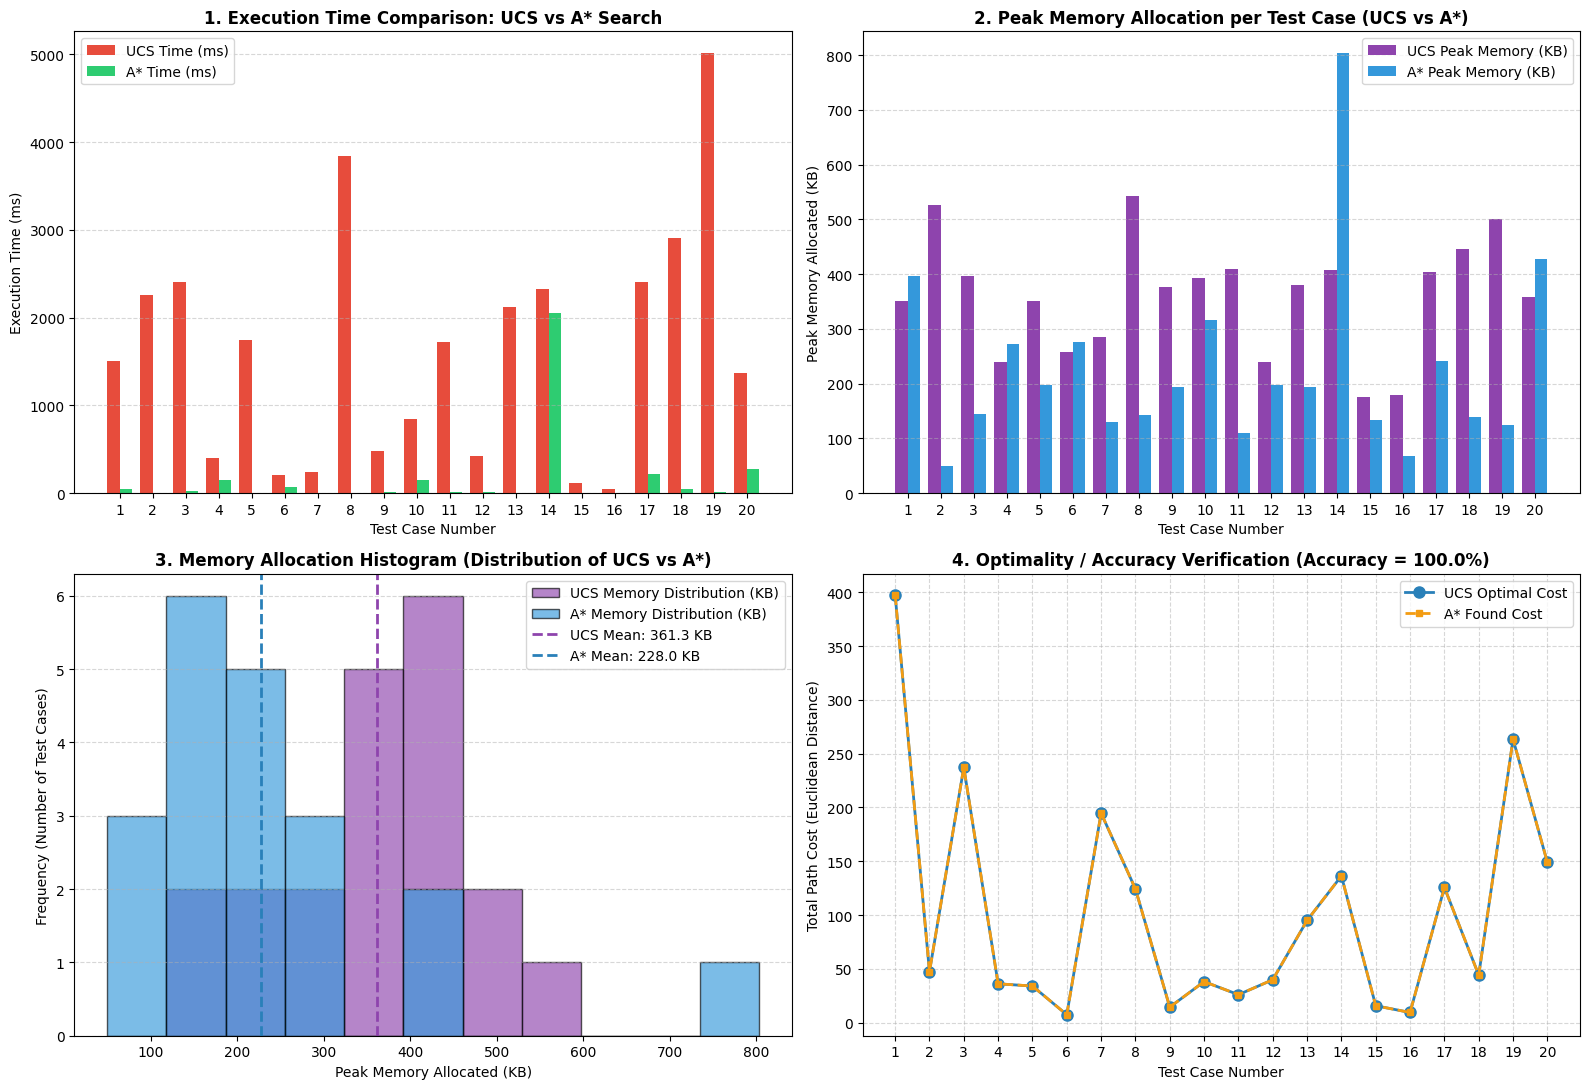

In [26]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
x = np.arange(len(results_df))
width = 0.38

# --- Plot 1: Execution Time Comparison (Bar Chart) ---
ax1 = axes[0, 0]
ax1.bar(x - width/2, results_df['UCS_Time_ms'], width, label='UCS Time (ms)', color='#e74c3c')
ax1.bar(x + width/2, results_df['AStar_Time_ms'], width, label='A* Time (ms)', color='#2ecc71')
ax1.set_xlabel('Test Case Number')
ax1.set_ylabel('Execution Time (ms)')
ax1.set_title('1. Execution Time Comparison: UCS vs A* Search', fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(results_df['Test'])
ax1.legend()
ax1.grid(axis='y', linestyle='--', alpha=0.5)

# --- Plot 2: Peak Memory Allocation per Test Case (Bar Histogram) ---
ax2 = axes[0, 1]
ax2.bar(x - width/2, results_df['UCS_Memory_KB'], width, label='UCS Peak Memory (KB)', color='#8e44ad')
ax2.bar(x + width/2, results_df['AStar_Memory_KB'], width, label='A* Peak Memory (KB)', color='#3498db')
ax2.set_xlabel('Test Case Number')
ax2.set_ylabel('Peak Memory Allocated (KB)')
ax2.set_title('2. Peak Memory Allocation per Test Case (UCS vs A*)', fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(results_df['Test'])
ax2.legend()
ax2.grid(axis='y', linestyle='--', alpha=0.5)

# --- Plot 3: Memory Allocation Frequency Distribution Histogram ---
ax3 = axes[1, 0]
bins = np.linspace(
    min(results_df['AStar_Memory_KB'].min(), results_df['UCS_Memory_KB'].min()),
    max(results_df['AStar_Memory_KB'].max(), results_df['UCS_Memory_KB'].max()),
    12
)
ax3.hist(results_df['UCS_Memory_KB'], bins=bins, alpha=0.65, label='UCS Memory Distribution (KB)', color='#8e44ad', edgecolor='black')
ax3.hist(results_df['AStar_Memory_KB'], bins=bins, alpha=0.65, label='A* Memory Distribution (KB)', color='#3498db', edgecolor='black')
ax3.axvline(results_df['UCS_Memory_KB'].mean(), color='#8e44ad', linestyle='dashed', linewidth=2, label=f"UCS Mean: {results_df['UCS_Memory_KB'].mean():.1f} KB")
ax3.axvline(results_df['AStar_Memory_KB'].mean(), color='#2980b9', linestyle='dashed', linewidth=2, label=f"A* Mean: {results_df['AStar_Memory_KB'].mean():.1f} KB")
ax3.set_xlabel('Peak Memory Allocated (KB)')
ax3.set_ylabel('Frequency (Number of Test Cases)')
ax3.set_title('3. Memory Allocation Histogram (Distribution of UCS vs A*)', fontweight='bold')
ax3.legend()
ax3.grid(axis='y', linestyle='--', alpha=0.5)

# --- Plot 4: Path Cost (Optimality/Accuracy Verification) ---
ax4 = axes[1, 1]
ax4.plot(results_df['Test'], results_df['UCS_Cost'], 'o-', label='UCS Optimal Cost', color='#2980b9', linewidth=2, markersize=8)
ax4.plot(results_df['Test'], results_df['AStar_Cost'], 's--', label='A* Found Cost', color='#f39c12', linewidth=2, markersize=5)
ax4.set_xlabel('Test Case Number')
ax4.set_ylabel('Total Path Cost (Euclidean Distance)')
ax4.set_title(f'4. Optimality / Accuracy Verification (Accuracy = {accuracy_score:.1f}%)', fontweight='bold')
ax4.set_xticks(results_df['Test'])
ax4.legend()
ax4.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

##Visualization using Video

In [27]:
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display
import numpy as np

# 1. Pick a multi-hop test case from your results_df (e.g., first row with >= 2 hops)
multi_hop_rows = results_df[results_df['Hops'] >= 2]
sample_row = multi_hop_rows.iloc[0] if len(multi_hop_rows) > 0 else results_df.iloc[0]

vis_start = int(sample_row['Start'])
vis_goal = int(sample_row['Goal'])
vis_heuristics = compute_heuristics(node_coords, vis_goal)

print(f"🎬 Recording 18-second search animation for Start Node: {vis_start} -> Goal Node: {vis_goal} ...")

# 2. Run UCS and A* while recording the exact sequence of expanded nodes
def ucs_record(graph_weighted, start, goal):
    frontier = [(0, start, [start])]
    best_cost_found = {start: 0}
    expanded_order = []
    while len(frontier) > 0:
        best_index = 0
        for i in range(len(frontier)):
            if frontier[i][0] < frontier[best_index][0]:
                best_index = i
        cost, node, path = frontier.pop(best_index)
        expanded_order.append(node)
        if node == goal:
            return path, expanded_order
        for neighbor, weight in graph_weighted[node]:
            new_cost = cost + weight
            if neighbor not in best_cost_found or new_cost < best_cost_found[neighbor]:
                best_cost_found[neighbor] = new_cost
                frontier.append((new_cost, neighbor, path + [neighbor]))
    return None, expanded_order

def astar_record(graph_weighted, heuristics, start, goal):
    frontier = [(heuristics[start], 0, start, [start])]
    best_g_found = {start: 0}
    expanded_order = []
    while len(frontier) > 0:
        best_index = 0
        for i in range(len(frontier)):
            if frontier[i][0] < frontier[best_index][0]:
                best_index = i
        f, g, node, path = frontier.pop(best_index)
        expanded_order.append(node)
        if node == goal:
            return path, expanded_order
        for neighbour, weight in graph_weighted[node]:
            new_g = g + weight
            if neighbour not in best_g_found or new_g < best_g_found[neighbour]:
                best_g_found[neighbour] = new_g
                new_f = new_g + heuristics[neighbour]
                frontier.append((new_f, new_g, neighbour, path + [neighbour]))
    return None, expanded_order

ucs_path_vis, ucs_exp = ucs_record(graph_weighted, vis_start, vis_goal)
astar_path_vis, astar_exp = astar_record(graph_weighted, vis_heuristics, vis_start, vis_goal)

print(f" -> UCS expanded {len(ucs_exp)} nodes | A* expanded {len(astar_exp)} nodes.")

# 3. Prepare coordinates for plotting (X = Longitude, Y = Latitude)
all_lons = [node_coords[n][1] for n in node_coords]
all_lats = [node_coords[n][0] for n in node_coords]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), dpi=100)
fig.suptitle(f"Node Expansion Visualization: Start ({vis_start}) → Goal ({vis_goal})", fontsize=14, fontweight='bold')

for ax in (ax1, ax2):
    # Plot all graph nodes in light gray in the background
    ax.scatter(all_lons, all_lats, c='#dcdde1', s=12, alpha=0.5, label='Unvisited Nodes')
    # Plot Start Node (Blue Circle) and Goal Node (Red Star)
    ax.scatter(node_coords[vis_start][1], node_coords[vis_start][0], c='#2980b9', s=160, marker='o', zorder=6, edgecolors='black', label='Start Node')
    ax.scatter(node_coords[vis_goal][1], node_coords[vis_goal][0], c='#e74c3c', s=220, marker='*', zorder=6, edgecolors='black', label='Goal Node')
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.grid(True, linestyle='--', alpha=0.3)

# Dynamic scatter & path line objects for UCS (Left) and A* (Right)
ucs_scat = ax1.scatter([], [], c='#f39c12', s=30, alpha=0.85, zorder=4, label='Expanded Nodes')
ucs_line, = ax1.plot([], [], c='#2ecc71', linewidth=3, zorder=5, label='Optimal Path')
ax1.legend(loc='lower left', fontsize=8)

astar_scat = ax2.scatter([], [], c='#f39c12', s=30, alpha=0.85, zorder=4, label='Expanded Nodes')
astar_line, = ax2.plot([], [], c='#2ecc71', linewidth=3, zorder=5, label='Optimal Path')
ax2.legend(loc='lower left', fontsize=8)

# 4. Configure Animation Frames: 150 search frames (15s) + 30 pause frames (3s) = 18 seconds at 10 FPS
TOTAL_SEARCH_FRAMES = 150
PAUSE_FRAMES = 30
total_frames = TOTAL_SEARCH_FRAMES + PAUSE_FRAMES
step_size = max(1, int(np.ceil(len(ucs_exp) / TOTAL_SEARCH_FRAMES)))

def update(frame):
    idx = min((frame + 1) * step_size, len(ucs_exp))

    # Update UCS expansion
    u_nodes = ucs_exp[:idx]
    u_coords = np.column_stack(([node_coords[n][1] for n in u_nodes], [node_coords[n][0] for n in u_nodes]))
    ucs_scat.set_offsets(u_coords)
    ucs_status = "FINISHED! ✅" if idx >= len(ucs_exp) else "Searching..."
    ax1.set_title(f"UCS (Blind Search) — Expanded: {len(u_nodes)} / {len(ucs_exp)} ({ucs_status})")

    if idx >= len(ucs_exp) and ucs_path_vis:
        ucs_line.set_data([node_coords[n][1] for n in ucs_path_vis], [node_coords[n][0] for n in ucs_path_vis])

    # Update A* expansion (at the exact same step speed for fair comparison!)
    a_idx = min((frame + 1) * step_size, len(astar_exp))
    a_nodes = astar_exp[:a_idx]
    a_coords = np.column_stack(([node_coords[n][1] for n in a_nodes], [node_coords[n][0] for n in a_nodes]))
    astar_scat.set_offsets(a_coords)
    astar_status = "FINISHED! ✅" if a_idx >= len(astar_exp) else "Searching..."
    ax2.set_title(f"A* (Informed Search) — Expanded: {len(a_nodes)} / {len(astar_exp)} ({astar_status})")

    if a_idx >= len(astar_exp) and astar_path_vis:
        astar_line.set_data([node_coords[n][1] for n in astar_path_vis], [node_coords[n][0] for n in astar_path_vis])

    return ucs_scat, ucs_line, astar_scat, astar_line

anim = animation.FuncAnimation(fig, update, frames=total_frames, interval=100, blit=False)
plt.close(fig)

# 5. Save as MP4 video & also display interactive video player inside Colab
video_filename = 'ucs_vs_astar_search_18s.mp4'
anim.save(video_filename, writer='ffmpeg', fps=10)
print(f"✅ 18-second video saved as '{video_filename}'! Displaying interactive player below:\n")

display(HTML(anim.to_html5_video()))

🎬 Recording 18-second search animation for Start Node: 1518 -> Goal Node: 250 ...
 -> UCS expanded 2628 nodes | A* expanded 34 nodes.


/tmp/ipykernel_5088/2051211049.py:126: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  anim.save(video_filename, writer='ffmpeg', fps=10)


✅ 18-second video saved as 'ucs_vs_astar_search_18s.mp4'! Displaying interactive player below:



/tmp/ipykernel_5088/2051211049.py:129: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  display(HTML(anim.to_html5_video()))
